# Interactive Blender Control (bpy kernel)
This notebook runs inside a Blender-capable kernel (`import bpy`) and can auto-repair gray Molecular Nodes scenes by reloading a styled molecule from the exported PDB.

In [1]:
from pathlib import Path
import subprocess
import sys

try:
    import bpy
    from mathutils import Vector
except Exception as exc:
    raise RuntimeError(
        'This notebook must run in Blender Python (bpy). '
        'Use kernel: blender.'
    ) from exc

try:
    import molecularnodes as mn
except Exception:
    mn = None

scene_path = Path('/Users/mb/Documents/blender_bridge/1A3N_scene.blend')
structure_path = Path('/Users/mb/Documents/blender_bridge/1A3N_bundle/structures/1A3N.pdb')
target_name = '1A3N'
if not scene_path.exists():
    raise FileNotFoundError(f'Scene not found: {scene_path}')


def node_group_is_stub(obj):
    if obj is None:
        return False
    for modifier in obj.modifiers:
        if modifier.type != 'NODES' or modifier.node_group is None:
            continue
        if len(modifier.node_group.nodes) <= 2:
            return True
    return False


def ensure_fallback_material():
    mat = bpy.data.materials.get('BridgeNotebookVisible')
    if mat is None:
        mat = bpy.data.materials.new('BridgeNotebookVisible')

    mat.use_nodes = True
    tree = mat.node_tree
    for node in list(tree.nodes):
        tree.nodes.remove(node)

    out = tree.nodes.new('ShaderNodeOutputMaterial')
    bsdf = tree.nodes.new('ShaderNodeBsdfPrincipled')
    bsdf.inputs['Base Color'].default_value = (0.12, 0.72, 0.95, 1.0)
    bsdf.inputs['Roughness'].default_value = 0.35
    if 'Alpha' in bsdf.inputs:
        bsdf.inputs['Alpha'].default_value = 1.0
    tree.links.new(bsdf.outputs['BSDF'], out.inputs['Surface'])

    if hasattr(mat, 'blend_method'):
        mat.blend_method = 'OPAQUE'
    return mat


def apply_fallback_material(obj):
    mat = ensure_fallback_material()

    if len(obj.data.materials) == 0:
        obj.data.materials.append(mat)
    else:
        for i in range(len(obj.data.materials)):
            obj.data.materials[i] = mat

    for modifier in obj.modifiers:
        if modifier.type != 'NODES' or modifier.node_group is None:
            continue
        for node in modifier.node_group.nodes:
            if not node.name.startswith('Style'):
                continue
            sock = node.inputs.get('Material')
            if sock is None:
                continue
            try:
                sock.default_value = mat
            except Exception:
                pass


def hide_non_target_meshes(target):
    for obj in bpy.data.objects:
        if obj.type != 'MESH' or obj.name == target.name:
            continue
        obj.hide_viewport = True
        obj.hide_render = True
        try:
            obj.hide_set(True)
        except Exception:
            pass


def load_molecule_with_style(pdb_path: Path, object_name: str):
    if mn is None:
        raise RuntimeError(
            'molecularnodes is not installed in this kernel. '
            'Run: pixi install && pixi run install-bpy-kernel'
        )

    try:
        mn.register()
    except Exception:
        pass

    last_error = None
    molecule = None
    for attempt in range(2):
        try:
            molecule = mn.entities.Molecule.load(pdb_path, name=object_name)
            break
        except Exception as exc:
            last_error = exc
            if attempt == 0 and 'setup_ccd' in str(exc).lower():
                subprocess.run([sys.executable, '-m', 'biotite.setup_ccd'], check=True)
                continue
            raise

    if molecule is None:
        raise RuntimeError(f'Failed to load molecule: {last_error}')

    styled_obj = bpy.data.objects.get(object_name) or getattr(molecule, 'object', None)
    style_errors = []
    style_variants = [
        ('cartoon', 'common'),
        ('spheres', 'common'),
        ('sticks', 'common'),
        ('cartoon', None),
    ]
    for style_name, color_name in style_variants:
        try:
            if color_name is None:
                molecule.add_style(style_name)
            else:
                molecule.add_style(style_name, color=color_name)
            styled_obj = bpy.data.objects.get(object_name) or getattr(molecule, 'object', None)
            if styled_obj is not None and not node_group_is_stub(styled_obj):
                break
        except Exception as exc:
            style_errors.append(f'{style_name}/{color_name}: {exc}')

    if styled_obj is None:
        raise RuntimeError('Molecule loaded but Blender object was not created.')
    if node_group_is_stub(styled_obj):
        raise RuntimeError('Molecule loaded but style graph is still empty: ' + ' | '.join(style_errors))

    return styled_obj


bpy.ops.wm.open_mainfile(filepath=str(scene_path))
scene = bpy.context.scene
view_layer = bpy.context.view_layer

for obj in bpy.data.objects:
    obj.hide_viewport = False
    obj.hide_render = False
    try:
        obj.hide_set(False)
    except Exception:
        pass

target = bpy.data.objects.get(target_name)

# Rebuild if the loaded scene does not have a usable styled molecule.
if target is None or node_group_is_stub(target):
    if not structure_path.exists():
        raise RuntimeError(
            f'Scene has no usable styled molecule and structure file is missing: {structure_path}'
        )

    if target is not None:
        mesh_data = target.data
        bpy.data.objects.remove(target, do_unlink=True)
        if mesh_data is not None and getattr(mesh_data, 'users', 0) == 0:
            bpy.data.meshes.remove(mesh_data)

    target = load_molecule_with_style(structure_path, target_name)

if target is None:
    meshes = [o for o in bpy.data.objects if o.type == 'MESH' and o.name.lower() != 'cube']
    if not meshes:
        raise RuntimeError('No molecular mesh object found (expected 1A3N).')
    target = meshes[0]

hide_non_target_meshes(target)

for o in view_layer.objects:
    o.select_set(False)
target.select_set(True)
view_layer.objects.active = target

cam = bpy.data.objects.get('PyMOL_Camera') or scene.camera
if cam is not None and cam.type == 'CAMERA':
    scene.camera = cam

    if target.type == 'MESH' and target.data.vertices:
        coords = [target.matrix_world @ v.co for v in target.data.vertices]
        min_x = min(v.x for v in coords)
        min_y = min(v.y for v in coords)
        min_z = min(v.z for v in coords)
        max_x = max(v.x for v in coords)
        max_y = max(v.y for v in coords)
        max_z = max(v.z for v in coords)
        center = Vector(((min_x + max_x) * 0.5, (min_y + max_y) * 0.5, (min_z + max_z) * 0.5))
        radius = max(1e-6, max(max_x - min_x, max_y - min_y, max_z - min_z) * 0.5)

        distance = (cam.matrix_world.translation - center).length
        if distance > radius * 100.0:
            forward = cam.matrix_world.to_quaternion() @ Vector((0.0, 0.0, -1.0))
            target_distance = max(radius * 8.0, 0.25)
            cam.location = center - forward * target_distance
            cam.data.clip_start = max(1e-4, min(cam.data.clip_start, radius * 0.02))
            cam.data.clip_end = max(cam.data.clip_start + 1e-3, max(cam.data.clip_end, target_distance + radius * 20.0))

# In bpy>=5 kernels, Molecular Nodes default shader can appear transparent/gray.
if bpy.app.version >= (5, 0, 0):
    apply_fallback_material(target)
    print('Applied notebook fallback material for bpy>=5.x.')

wm = bpy.context.window_manager
if wm.windows:
    window = wm.windows[0]
    for area in window.screen.areas:
        if area.type != 'VIEW_3D':
            continue
        region = next((r for r in area.regions if r.type == 'WINDOW'), None)
        if region is None:
            continue
        space = area.spaces.active
        if space.type != 'VIEW_3D':
            continue
        with bpy.context.temp_override(
            window=window,
            area=area,
            region=region,
            scene=scene,
            view_layer=view_layer,
            active_object=target,
            selected_objects=[target],
            selected_editable_objects=[target],
        ):
            try:
                space.shading.type = 'MATERIAL'
            except Exception:
                pass
            try:
                bpy.ops.view3d.view_selected(use_all_regions=False)
            except Exception:
                pass
            if scene.camera is not None:
                space.region_3d.view_perspective = 'CAMERA'

bpy.ops.wm.save_as_mainfile(filepath=str(scene_path))
print(f'Focused object: {target.name}')
print(f'Saved scene: {scene_path}')



00:01.261  blend            | Read blend: "/Users/mb/Documents/blender_bridge/1A3N_scene.blend"
Applied notebook fallback material for bpy>=5.x.
Info: Saved as "1A3N_scene.blend"
Focused object: 1A3N
Saved scene: /Users/mb/Documents/blender_bridge/1A3N_scene.blend


/var/folders/61/mzlpdp3j4dbdpdb2xmz4w3wc0000gn/T/ipykernel_68717/413074996.py:42: DeprecationWarning: 'Material.use_nodes' is expected to be removed in Blender 6.0
  mat.use_nodes = True


02:17.904  render           | Saved: '/var/folders/61/mzlpdp3j4dbdpdb2xmz4w3wc0000gn/T/tmpbz_9ndab.png'
Rendered preview: /var/folders/61/mzlpdp3j4dbdpdb2xmz4w3wc0000gn/T/tmpbz_9ndab.png
Non-gray fraction: 0.388


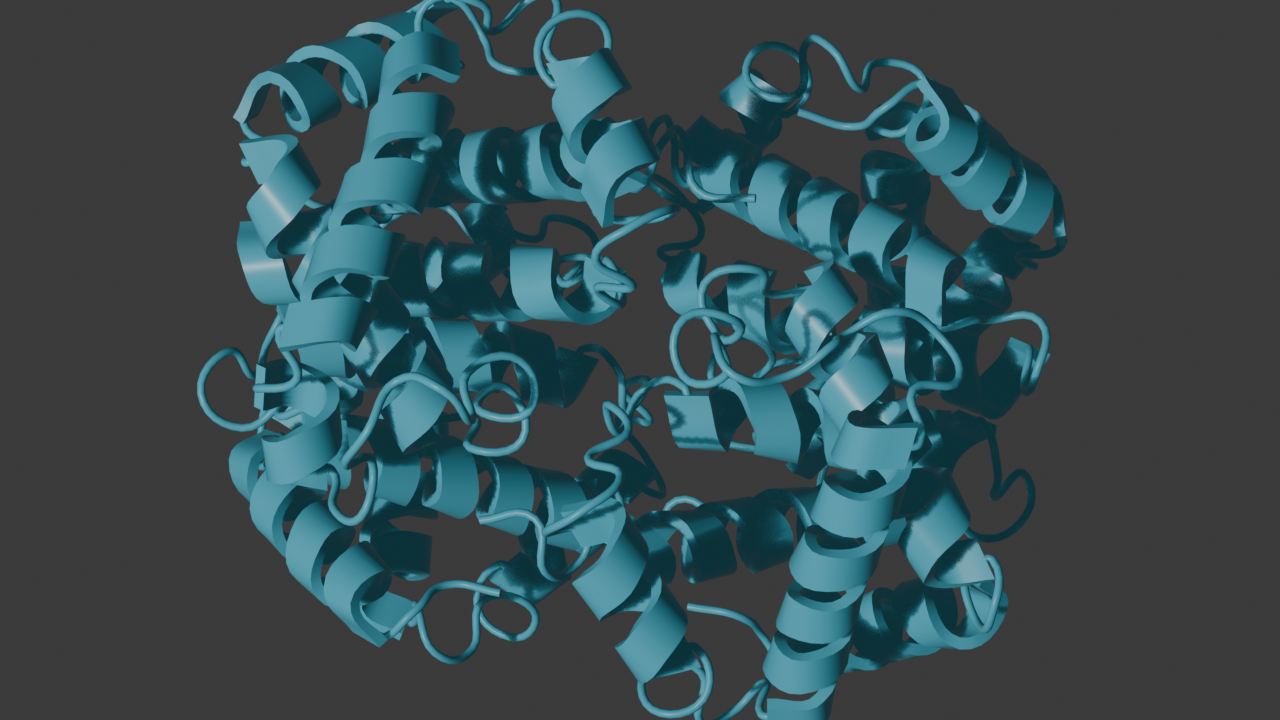

In [7]:
import tempfile
from pathlib import Path
from IPython.display import Image, display

import numpy as np
from PIL import Image as PILImage

tmp_png = Path(tempfile.NamedTemporaryFile(suffix='.png', delete=False).name)
scene = bpy.context.scene
scene.render.resolution_x = 1280
scene.render.resolution_y = 720
scene.render.image_settings.file_format = 'PNG'
scene.render.filepath = str(tmp_png)
bpy.ops.render.render(animation=False, write_still=True)

img = np.asarray(PILImage.open(tmp_png).convert('RGB')).astype(np.int16)
non_gray = ((
    np.abs(img[:, :, 0] - img[:, :, 1])
    + np.abs(img[:, :, 1] - img[:, :, 2])
    + np.abs(img[:, :, 0] - img[:, :, 2])
) > 12).mean()

print(f'Rendered preview: {tmp_png}')
print(f'Non-gray fraction: {non_gray:.3f}')
display(Image(filename=str(tmp_png)))

